In [1]:
#1. LOADING THE DATASET
import pandas as pd
df=pd.read_csv("Sales_transactions_2022_2025.csv")


In [2]:
#2. IMPORTING THE LIBRARIES
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import warnings
warnings.filterwarnings("ignore")


In [3]:
#2.1. SETTING UP THE CHARTS STYLES
plt.style.use("seaborn-v0_8-darkgrid")
sns.set_palette("husl")

In [4]:
#2.2. READING THE CSV
print(df.head())

  Transaction_ID  Order_ID Customer_ID Customer_Name  Customer_Age  \
0      T02016694  O0116694      C01482  Sophia Smith          28.0   
1      T02016374  O0108187      C01591   Hannah King          46.0   
2      T02004099  O0104099      C04140   Emma Wilson          42.0   
3      T02010280  O0110280      C03663  Daniel Clark          18.0   
4      T02012685  O0112685      C02749  Sophia Smith          37.0   

  Customer_Gender    Customer_Segment  Order_Date Order_Time Sales_Channel  \
0            Male            Consumer  2022-10-06   11:30:55        Online   
1          Female            Consumer  2024-06-03   17:06:29        Online   
2            Male            Consumer  2024-12-19   08:22:11        Online   
3            Male           Corporate  2025-10-05   14:32:43    B2B Portal   
4            Male  Returning Customer  2022-09-13   14:55:16    B2B Portal   

   ... Order_Status Shipping_Method Delivery_Days Return_Flag Return_Reason  \
0  ...    Completed        Stan

In [5]:
# 3. EXPLORATORY DATASET ANALYSIS
print("="*50)
print("INITIAL EXPLORATORY ANALYSIS")
print("="*50)

#3.1. DATASET OVERVIEW
print(f"\n Dimensions of the Dataset: {df.shape}")
print(f"\n First 5 lines:")
print(df.head())
print(f"\n Last 5 lines:")
print(df.tail())

#3.2. INFORMATION OF THE DATA
print("\n Information of the Data:")
print(df.info())

#3.3. DESCRIPTIVE STATISTICS
print("\n Descripte Statistics (Numerical Variables):")
print(df.describe())

#3.4. CHECKING FOR NULL VALUES BY COLUMNS
print(f"\n Null Values by Columns: \n{df.isnull().sum()}")

INITIAL EXPLORATORY ANALYSIS

 Dimensions of the Dataset: (18045, 36)

 First 5 lines:
  Transaction_ID  Order_ID Customer_ID Customer_Name  Customer_Age  \
0      T02016694  O0116694      C01482  Sophia Smith          28.0   
1      T02016374  O0108187      C01591   Hannah King          46.0   
2      T02004099  O0104099      C04140   Emma Wilson          42.0   
3      T02010280  O0110280      C03663  Daniel Clark          18.0   
4      T02012685  O0112685      C02749  Sophia Smith          37.0   

  Customer_Gender    Customer_Segment  Order_Date Order_Time Sales_Channel  \
0            Male            Consumer  2022-10-06   11:30:55        Online   
1          Female            Consumer  2024-06-03   17:06:29        Online   
2            Male            Consumer  2024-12-19   08:22:11        Online   
3            Male           Corporate  2025-10-05   14:32:43    B2B Portal   
4            Male  Returning Customer  2022-09-13   14:55:16    B2B Portal   

   ... Order_Status Shi

In [6]:
#4. DATA CLEANING AND PROCESSING
print("\n"+"="*50)
print("DATA CLEANING AND PROCESSING")
print("="*50)

#4.1. FILLING NULL VALUES
# Create a Dictionary for Mapping Names to Product_ID and Product_Name
mapeamento_prod_names=df.dropna(subset=["Product_Name"]).set_index("Product_ID")["Product_Name"].to_dict()

# Filling Null Values with the Mapping of Names
df["Product_Name"]=df["Product_Name"].fillna(df["Product_Name"].map(mapeamento_prod_names))
print(f"\n Empty Cells in the Product_Name column:\n{df["Product_Name"].isnull().sum()}")

# Cheking if there are Product_IDs without Product_Names 
IDs_sem_nome=df[df["Product_Name"].isnull()]["Product_ID"].unique()
print("IDs that have not nomes:", IDs_sem_nome)

#In this case, Give the name "Unknown Product" to Products without Names
df["Product_Name"]=df["Product_Name"].fillna("Unknown Product")
print(f"\n Empty Cells in the Product_Name column:\n {df["Product_Name"].isnull().sum()}")

# Filling Null CUSTOMER_NAMES 
df["Customer_Name"]=df["Customer_Name"].fillna("Unknown Customer")
print(f"\n Empty Cells in the Customer_Name Column:\n {df["Customer_Name"].isnull().sum()}")

#Filling Null Customer_age
df["Customer_Age"]=df["Customer_Age"].fillna(df["Customer_Age"].median())
print(f"\n Empty Cells in the Customer_Age Column:\n {df["Customer_Age"].isnull().sum()}")

#Filling Null Customer_gender
df["Customer_Gender"]=df["Customer_Gender"].fillna(df["Customer_Gender"].mode()[0])
print(f"\n Empty Cells in the Customer_Gender column:\n {df["Customer_Gender"].isnull().sum()}")

#Filling Null Payment_Method
df["Payment_Method"]=df["Payment_Method"].fillna(df["Payment_Method"].mode()[0])
print(f"\n Empty Cells in the Payment_Method Column:\n {df["Payment_Method"].isnull().sum()}")

#Filling Null Delivery_Days
df["Delivery_Days"]=df["Delivery_Days"].fillna(df["Delivery_Days"].median())
print(f"\n Empty Cells in the Delivery_Days Column:\n {df["Delivery_Days"].isnull().sum()}")

#Fill Empty Cells in the Return_Reason Column
df["Return_Reason"]=df["Return_Reason"].fillna("Not Returned")
print(f"\n Empty Cells in the Return_Reason Column:\n {df["Return_Reason"].isnull().sum()}")

#Fill Empty Cells in the Promotion_Code Column
df["Promotion_Code"]=df["Promotion_Code"].fillna("None")
print(f"\n Empty Cells in the Promotion_Code Column:\n {df["Promotion_Code"].isnull().sum()}")

#Fill Empty Cells in the Customer_Rating Column
df["Customer_Rating"]=df["Customer_Rating"].fillna(df["Customer_Rating"].median())
print(f"\n Empty Cells in the Customer_Rating Column:\n {df["Customer_Rating"].isnull().sum()}")

#Fill Empty Cells in the Inventory_Level Column
df["Inventory_Level"]=df["Inventory_Level"].fillna(
    df.groupby("Product_ID")["Inventory_Level"].transform("median")
)
print(f"\n Empty Cells in the Inventory_Level Column:\n {df["Inventory_Level"].isnull().sum()}")


DATA CLEANING AND PROCESSING

 Empty Cells in the Product_Name column:
144
IDs that have not nomes: <StringArray>
['P003', 'P019', 'P026', 'P018', 'P004', 'P008', 'P025', 'P015', 'P009',
 'P007', 'P005', 'P023', 'P024', 'P021', 'P020', 'P002', 'P011', 'P028',
 'P001', 'P013', 'P014', 'P012', 'P010', 'P017', 'P022', 'P016', 'P006']
Length: 27, dtype: str

 Empty Cells in the Product_Name column:
 0

 Empty Cells in the Customer_Name Column:
 0

 Empty Cells in the Customer_Age Column:
 0

 Empty Cells in the Customer_Gender column:
 0

 Empty Cells in the Payment_Method Column:
 0

 Empty Cells in the Delivery_Days Column:
 0

 Empty Cells in the Return_Reason Column:
 0

 Empty Cells in the Promotion_Code Column:
 0

 Empty Cells in the Customer_Rating Column:
 0

 Empty Cells in the Inventory_Level Column:
 0


In [7]:
#4.2. Checking for Unique Values in Categorical Columns
categorical_columns=["Product_Name","Customer_Gender","Payment_Method","Return_Reason","Promotion_Code", "Sales_Channel", "Store_Name", "Country", "Region", "City", "Product_Category", "Product_Subcategory", "Order_Status", "Shipping_Method", "Return_Flag", "Sales_Representative"]
print("\n Unique Values in Categorical Columns:")
for col in categorical_columns:
    unique_values=df[col].unique()
    print(f"\n Column: {col}\n Unique Values: {unique_values}")


 Unique Values in Categorical Columns:

 Column: Product_Name
 Unique Values: <StringArray>
[          'Webcam HD',     'Office Keyboard',      'Copy Paper Box',
     'SmartDock USB-C',           'Desk Lamp',       'Ergo Footrest',
     'Security Camera',   'EdgeTab 11 Tablet',     'Precision Mouse',
   'ProBook 16 Laptop',            'Desk Fan',    'Office Chair Pro',
   'Vision 27 Monitor',    'Backup Drive 2TB',        'Air Purifier',
        'Premium Pens',       'USB Power Hub',        'Printer Plus',
         'Laser Toner',    'Presentation Kit',  'AeroBook 14 Laptop',
       'Notebook Pack',     'Portable Heater',      'Filing Cabinet',
 'NoiseCancel Headset',      'Coffee Machine',       'Meeting Table',
       'Standing Desk',     'Unknown Product']
Length: 29, dtype: str

 Column: Customer_Gender
 Unique Values: <StringArray>
['Male', 'Female', 'Non-binary', 'male', 'FEMALE', 'Non Binary']
Length: 6, dtype: str

 Column: Payment_Method
 Unique Values: <StringArray>
[  'Credi


 Column: Country
 Unique Values: <StringArray>
['United States', 'Australia', 'France', 'Canada', 'United Kingdom',
 'Germany']
Length: 6, dtype: str

 Column: Region
 Unique Values: <StringArray>
[                  'West',        'New South Wales',          'Île-de-France',
              'Northeast',                'Midwest',                'Ontario',
       'British Columbia',                  'South',                'England',
 'North Rhine-Westphalia',                'Bavaria',             'North East',
       'British columbia',                    'NRW']
Length: 14, dtype: str

 Column: City
 Unique Values: <StringArray>
['LOS ANGELES',      'Sydney',       'Paris',    'New York',     'Chicago',
     'Toronto',   'Vancouver',      'Austin',      'London',     'Cologne',
 'Los Angeles',  'Manchester',  ' New York ',      'Munich',      'munich']
Length: 15, dtype: str

 Column: Product_Category
 Unique Values: <StringArray>
[    'Electronics', 'Office Supplies',       'Furniture',

In [8]:
#4.2.1 Data Normalization
## Dictionary for Mapping Customer_Gender to Replace Inconsistent Values
gender_mapping={"male":"Male","FEMALE":"Female","Non Binary":"Non-binary","Non_binary":"Non-binary"}
df["Customer_Gender"]=df["Customer_Gender"].replace(gender_mapping)
print(f"\n Unique Values in Customer_Gender after Normalization:\n {df["Customer_Gender"].unique()}")

## Dictionary for Mapping Payment_Method to Replace Inconsistent Values
payment_mapping={"DebitCard":"Debit Card","paypal":"PayPal","Bank transfer":"Bank Transfer","credit card":"Credit Card"}
df["Payment_Method"]=df["Payment_Method"].replace(payment_mapping)
print(f"\n Unique Values in Payment_Method after Normalization:\n {df["Payment_Method"].unique()}")

## Dictionary for Mapping Region to Replace Inconsistent Values
region_mapping={"North East":"Northeast", "British columbia":"British Columbia","NRW":"North Rhine-Westphalia"}
df["Region"]=df["Region"].replace(region_mapping)
print(f"\n Unique Values in Region after Normalization:\n {df["Region"].unique()}")

## Dictionary for Mapping City to Replace Inconsistent Values
city_mapping={"LOS ANGELES":"Los Angeles","munich":"Munich"}
df["City"]=df["City"].replace(city_mapping)
print(f"\n Unique Values in City after Normalization:\n {df["City"].unique()}")

## Dictionary for Mapping Product_Category to Replace Inconsistent Values
category_mapping={'FURNITURE':"Furniture",'electronics':"Electronics","Office supplies":"Office Supplies"}
df["Product_Category"]=df["Product_Category"].replace(category_mapping)
print(f"\n Unique Values in Product_Category after Normalization:\n {df["Product_Category"].unique()}")

## Dictionary for Mapping Order_Status to Replace Inconsistent Values
order_status_mapping={'SHIPPED':"Shipped",'completed':"Completed","processing":"Processing"}
df["Order_Status"]=df["Order_Status"].replace(order_status_mapping)
print(f"\n Unique Values in Order_Status after Normalization:\n {df["Order_Status"].unique()}")



 Unique Values in Customer_Gender after Normalization:
 <StringArray>
['Male', 'Female', 'Non-binary']
Length: 3, dtype: str

 Unique Values in Payment_Method after Normalization:
 <StringArray>
['Credit Card', 'Debit Card', 'PayPal', 'Apple Pay', 'Cash', 'Bank Transfer']
Length: 6, dtype: str

 Unique Values in Region after Normalization:
 <StringArray>
[                  'West',        'New South Wales',          'Île-de-France',
              'Northeast',                'Midwest',                'Ontario',
       'British Columbia',                  'South',                'England',
 'North Rhine-Westphalia',                'Bavaria']
Length: 11, dtype: str

 Unique Values in City after Normalization:
 <StringArray>
['Los Angeles',      'Sydney',       'Paris',    'New York',     'Chicago',
     'Toronto',   'Vancouver',      'Austin',      'London',     'Cologne',
  'Manchester',  ' New York ',      'Munich']
Length: 13, dtype: str

 Unique Values in Product_Category after Normal

In [9]:
#4.3. Converting Order_Date to Datetime Format
df["Order_Date"]=pd.to_datetime(df["Order_Date"],format="%Y-%m-%d")
print("Order_Date converted to Datetime Format successfully.")

#4.4. Checking for Duplicate Rows
duplicate_rows=df.duplicated().sum()
print(f"\n Duplicate Rows in the Dataset: {duplicate_rows}")

#4.5. Removing Duplicate Rows
if duplicate_rows>0:
    df=df.drop_duplicates()
    print(f"\n Duplicate Rows Removed. New Dataset Shape: {df.shape}")

#4.6. Checking if Sales_Amount is (Quantity * Unit_Price)
gross_test=df['Unit_Price'] * df['Quantity']
Value_with_discount = gross_test * (1 - df['Discount_Percentage']/100)
print(f"\n Checking if Value_with_discount is equal to Sales_amount\n Value with Discount:\n {Value_with_discount.head()}", f"\n Sales_Amount:\n {df['Sales_Amount'].head()}")
 

Order_Date converted to Datetime Format successfully.

 Duplicate Rows in the Dataset: 45

 Duplicate Rows Removed. New Dataset Shape: (18000, 36)

 Checking if Value_with_discount is equal to Sales_amount
 Value with Discount:
 0     162.051
1     300.135
2      74.664
3    1078.429
4     237.014
dtype: float64 
 Sales_Amount:
 0     162.05
1     300.13
2      74.66
3    1078.46
4     237.03
Name: Sales_Amount, dtype: float64


In [10]:
#5. STATISTICAL AND BUSINESS ANALYTICS

print("\n"+"="*50)
print("STATISTICAL AND BUSINESS ANALYTICS")
print("="*50)


#5.1. RENTABILITY AND FINANCIAL HEALTH
print("======== RENTABILITY AND FINANCIAL HEALTH ========") 
#5.1.1. PROFIT MARGIN BY CATEGORY
print("===Profit Margin by Category===")
# Grouping the Data to see Total Revenue and Profit by Category
category_profit=df.groupby("Product_Category")[["Sales_Amount", "Profit"]].sum().reset_index()

#Creating Profit Margin Column (%)
category_profit["Profit_Margin_%"]=(category_profit["Profit"]/category_profit["Sales_Amount"])*100

#Grouping to see which gives more profit
category_profit=category_profit.sort_values(by="Profit", ascending=False)
print("--- Revenue, Profit and Margin by Category ---")
print(category_profit)

#5.1.2. IMPACT OF DISCOUNTS ON PROFITABILITY
#Creating Discounts Range
df["Discount_Range"]=pd.cut(
    df["Discount_Percentage"],
    bins=[-1, 0, 10, 20, 30, 50, 100],
    labels=["0%", "1-10%", "11-20%", "21-30%", "31-50%", ">50%"]
)
discounts_impact=df.groupby("Discount_Range", observed=True).agg(
    Profit_mean=("Profit", "mean"),
    Total_revenue=("Sales_Amount", "sum"),
    Quantity_sold=("Quantity", "sum"),
    Total_profit=("Profit", "sum")
).reset_index()

discounts_impact['Margin_%']=(discounts_impact["Total_profit"] / discounts_impact["Total_revenue"]) * 100
print("\n === Impact of Discounts ===")
columns_to_show = ['Discount_Range', 'Profit_mean', 'Quantity_sold', 'Margin_%']
print(discounts_impact[columns_to_show])

#5.1.3. COST VS REVENUE (MARKUP ANALYSIS)
#Grouping cost and revenue by Subcategory
cost_revenue = df.groupby("Product_Subcategory")[["Cost_Amount", "Sales_Amount"]].sum().reset_index()
#Creating Markup Column (Revenue / Cost)
cost_revenue["Markup"] = cost_revenue["Sales_Amount"] / cost_revenue["Cost_Amount"]
top_cost_revenue = cost_revenue.sort_values(by="Cost_Amount", ascending=False).head(10)
print("\n === Top 10 Subcategories by Cost ===")
print(top_cost_revenue[["Product_Subcategory", "Cost_Amount", "Sales_Amount", "Markup"]])



STATISTICAL AND BUSINESS ANALYTICS
======== RENTABILITY AND FINANCIAL HEALTH ========
===Profit Margin by Category===
--- Revenue, Profit and Margin by Category ---
  Product_Category  Sales_Amount     Profit  Profit_Margin_%
1      Electronics    4922081.42  952110.92        19.343665
2        Furniture    1986144.85  420015.02        21.147250
3  Office Supplies     741774.85  144728.13        19.511059
0       Appliances     584089.48  128585.33        22.014663

 === Impact of Discounts ===
  Discount_Range  Profit_mean  Quantity_sold   Margin_%
0             0%   120.646407          16232  25.066458
1          1-10%    86.711622          14323  18.935135
2         11-20%    41.659011           7029  10.216812
3         21-30%     1.064207            687   0.276282
4         31-50%    94.020000              1  19.355237
5           >50%    48.680000              3  15.871153

 === Top 10 Subcategories by Cost ===
   Product_Subcategory  Cost_Amount  Sales_Amount    Markup
7       

In [11]:
#5.2. PRODUCTS PORTFOLIO PERFORMANCE

#5.2.1. ABC ANALYSIS (BILLING AND PROFITABILITY)
#Grouping by Product
product=df.groupby("Product_Name").agg(
    Total_Revenue=("Sales_Amount", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

#Sorting From Highest to Lowest Revenue
product=product.sort_values(by="Total_Revenue", ascending=False).reset_index(drop=True)

#Calculating Cumulative Revenue and Cumulative Profit (Percentage)
product["Cumulative_Revenue_%"] = product["Total_Revenue"].cumsum()/product["Total_Revenue"].sum() * 100

#Defining ABC Classes (Classic Rule: A=80%, B=95%, C=100%)
def classify_abc(percentage):
    if percentage <= 80:
        return "A (High Performance)"
    elif percentage <= 95:
        return "B (Medium Performance)"
    else:
        return "C (Low Performance)"
product["ABC_Class"] = product["Cumulative_Revenue_%"].apply(classify_abc)

#Printing the top 10 Products
print("\n === Top 10 Products by Revenue ===")
print(product[["Product_Name", "Total_Revenue", "Total_Profit", "Total_Quantity", "ABC_Class"]].head(10))

#5.2.2 AVERAGE PRICE BY CATEGORY VS RETURNING RATE
# Converting Return Flag into Numbe (1 for Yes, 0 for No)
df["Return_Numeric"]=df["Return_Flag"].map({"Yes":1, "No":0})
category_analysis=df.groupby("Product_Category").agg(
    Average_Price=("Unit_Price", "mean"),
    Return_Rate=("Return_Numeric", lambda x: x.mean()*100),
    Total_Revenue=("Sales_Amount", "sum")
).reset_index()
category_analysis=category_analysis.sort_values(by="Average_Price", ascending=False)
print("\n ===== AVERAGE PRICE VS RETURNING RATE BY CATEGORY=====")
print(category_analysis)

#5.2.3 HIGH-TURNOVER, LOW-MARGIN PRODUCTS
# Filtering high-turnover, low-margin Products
product["Margin_%"]=(product["Total_Profit"]/ product["Total_Revenue"])*100
top_turnover=product.sort_values(by="Total_Quantity", ascending=False).head(15)
print("\n ===== TOP 15 BEST SELLER PRODUCTS (VOLUME) ======")
print(top_turnover[["Product_Name", "Total_Quantity", "Total_Revenue", "Margin_%"]])



 === Top 10 Products by Revenue ===
         Product_Name  Total_Revenue  Total_Profit  Total_Quantity  \
0  AeroBook 14 Laptop     1382381.54     234632.00            1638   
1   ProBook 16 Laptop     1346439.33     251757.02            1111   
2   EdgeTab 11 Tablet      675690.83     100538.15            1439   
3       Standing Desk      588721.39     118578.66             894   
4       Meeting Table      530253.01      82509.73             623   
5   Vision 27 Monitor      455769.38      89674.53            1476   
6    Office Chair Pro      436645.44      95708.07            1041   
7        Printer Plus      255368.19      35772.50             967   
8        Air Purifier      236656.52      51163.35             783   
9      Filing Cabinet      222637.74      55425.35             960   

              ABC_Class  
0  A (High Performance)  
1  A (High Performance)  
2  A (High Performance)  
3  A (High Performance)  
4  A (High Performance)  
5  A (High Performance)  
6  A (High

In [12]:
#5.3. LOGISTICS AND OPERATIONS
#5.3.1. LOGISTIC PERFORMANCE BY REGION AND SHIPPING METHOD
#Calculating a Average and Standard Deviation (to see the consistency) of delivery days
logistic_region=df.groupby(["Region", "Shipping_Method"]).agg(
    Average_Days=("Delivery_Days", "mean"),
    Std_Dev_Days=("Delivery_Days", "std"),
    Qty_Orders=("Transaction_ID", "count")
).reset_index()

#Rounding to be more readable
logistic_region["Average_Days"]=logistic_region["Average_Days"].round(1)
logistic_region["Std_Dev_Days"]=logistic_region["Std_Dev_Days"].round(1)
print("===== AVERAGE DELIVERY TIME BY REGION E METHOD")
print(logistic_region.sort_values(by="Average_Days", ascending=False))

===== AVERAGE DELIVERY TIME BY REGION E METHOD
                    Region Shipping_Method  Average_Days  Std_Dev_Days  \
3                  Bavaria        Standard           4.6           1.6   
7         British Columbia        Standard           4.5           1.5   
11                 England        Standard           4.5           1.5   
15                 Midwest        Standard           4.5           1.5   
31                 Ontario        Standard           4.5           1.5   
27               Northeast        Standard           4.5           1.5   
43           Île-de-France        Standard           4.5           1.5   
35                   South        Standard           4.5           1.5   
19         New South Wales        Standard           4.5           1.5   
39                    West        Standard           4.4           1.5   
23  North Rhine-Westphalia        Standard           4.4           1.5   
4         British Columbia         Express           2.0         

In [13]:
#5.3.2. IS THE EXPRESS METHOD WORTH IT? (COMPARING COSTS VS DEADLINES)
#Comparing the delivery everage time by method (general, without separing region)
time_by_method=df.groupby("Shipping_Method")["Delivery_Days"].mean().reset_index().sort_values(by="Delivery_Days")
print("\n ===== GENERAL EVERAGE TIME BY DELIVERY METHOD =====")
print(time_by_method)

#5.3.3. STOCK MANAGEMENT: RISC OF BREAK
#Grouping by product: to see the average stock and the Total Quantity of Sales
stock_product=df.groupby("Product_Name").agg(
    Average_Stock=("Inventory_Level", "mean"),
    Total_Qty_Sales=("Quantity", "sum")
).reset_index()
stock_product["Turnover_Index"]=stock_product["Total_Qty_Sales"]/stock_product["Average_Stock"]
break_risc=stock_product[stock_product["Average_Stock"]>0].sort_values(by="Turnover_Index", ascending=False).head(15)
print("\n ===== TOP 15 PRODUCTS WITH RISC OF BREAK(HIGH TURNOVER/AVERAGE STOCK) =====")
print(break_risc[["Product_Name", "Average_Stock", "Total_Qty_Sales", "Turnover_Index"]].round(2))


 ===== GENERAL EVERAGE TIME BY DELIVERY METHOD =====
  Shipping_Method  Delivery_Days
2          Pickup       0.009656
1        Next Day       1.367756
0         Express       1.843921
3        Standard       4.495152

 ===== TOP 15 PRODUCTS WITH RISC OF BREAK(HIGH TURNOVER/AVERAGE STOCK) =====
           Product_Name  Average_Stock  Total_Qty_Sales  Turnover_Index
4        Copy Paper Box          70.33             2122           30.17
17      Precision Mouse          69.81             2052           29.39
25        USB Power Hub          69.46             1944           27.99
13        Notebook Pack          70.99             1979           27.88
18         Premium Pens          70.06             1918           27.38
10          Laser Toner          68.22             1781           26.11
15      Office Keyboard          69.84             1818           26.03
28            Webcam HD          69.58             1628           23.40
0    AeroBook 14 Laptop          70.20             1638

In [14]:
#5.4. CLIENT´S BIHAVIOR AND SATISFACTION (IS THE BEST CLIENT HAPPIER?)
#5.4.1. SATISFACTION VS SPENT
#Let´s Use the spent average by client and the Rating average
#Sorting by Rating Mark (Customer_Rating)
satisfaction=df.groupby("Customer_Rating").agg(
    Average_Spent=("Sales_Amount", "mean"),
    Qty_Buy=("Transaction_ID", "count")
).reset_index()
#Removing Null (NaN) Marks (Only for this Chart)
satisfaction=satisfaction.dropna(subset=["Customer_Rating"])
print("===== AVERAGE SPENT BY RATING MARK =====")
print(satisfaction.sort_values(by="Customer_Rating"))

#5.4.2. RETURNING ANALYSIS (Which Categories give problems?)
#Filtering the Returning only (Returnin_Flag =="yes")
returnings=df[df["Return_Flag"]=="Yes"]

#Couting the Return Reasons
returning_reasons=returnings["Return_Reason"].value_counts().reset_index()
returning_reasons.columns=["Reason", "Quantity"]
print("\n ===== TOP RETURN REASON =====")
print(returning_reasons)

#5.4.3. DEMOGRAPHIC PERFIL (who does buy more?)
#Creating Age groups
df["Age_group"]=pd.cut(df["Customer_Age"],
                       bins=[0, 25, 35, 45, 55, 100],
                       labels=["Till 25", "26-35", "36-45", "46-55", "55+"])
#Sorting by Age group and Gender to see the Total Revenue
demogr_perfil=df.groupby(["Age_group","Customer_Gender"], observed=True)["Sales_Amount"].sum().reset_index()
print("\n =====REVENUE BY AGE GROUP AND GENDER =====")
print(demogr_perfil.sort_values(by="Sales_Amount", ascending=False).head(10))



===== AVERAGE SPENT BY RATING MARK =====
   Customer_Rating  Average_Spent  Qty_Buy
0              1.0     405.669856      417
1              2.0     424.888073      898
2              3.0     456.946386     2316
3              4.0     466.302138     9214
4              5.0     451.713104     5155

 ===== TOP RETURN REASON =====
          Reason  Quantity
0  Late Delivery       331
1     Wrong Item       317
2        Damaged       312
3          Other       311
4      Defective       302
5   Changed Mind       300

 =====REVENUE BY AGE GROUP AND GENDER =====
   Age_group Customer_Gender  Sales_Amount
6      36-45          Female    1515075.53
7      36-45            Male    1357397.05
4      26-35            Male    1137393.27
3      26-35          Female    1051116.44
10     46-55            Male     803291.76
9      46-55          Female     800319.46
0    Till 25          Female     431295.53
1    Till 25            Male     421459.93
12       55+          Female     251150.24
13   

In [15]:
#5.5. CHANNEL, PAYMENT AND TEAM
#5.5.1. SALES CHANNEL PERFORMANCE(Online VS physical store vs b2b)
#Sorting by Sales Channel to see the Revenue, Profit and Margin
channels=df.groupby("Sales_Channel").agg(
    Total_Revenue=("Sales_Amount", "sum"),
    Total_Profit=("Profit", "sum"),
    Orders_Qty=("Transaction_ID", "count")
).reset_index()
channels["Margin_%"]=(channels["Total_Profit"]/channels["Total_Revenue"])*100
channels=channels.sort_values(by="Total_Revenue", ascending=False)
print("\n ===== SALES CHANNEL PERFORMANCE =====")
print(channels)

#5.5.2. PAYMENT PREFERENCES VS RETURNING RATE
#Creating numeric column for Return_Flag (1 for Yes, 0 for No)
df["Return_Numeric"]=df["Return_Flag"].map({"Yes":1, "No":0})
payments=df.groupby("Payment_Method").agg(
    Qty_Use=("Transaction_ID", "count"),
    Ticket_Average=("Sales_Amount", "mean"),
    Return_Rate=("Return_Numeric", lambda x: x.mean()*100)
).reset_index()
payments=payments.sort_values(by="Qty_Use", ascending=False)
print("\n ===== PAYMENT PREFERENCES VS RETURNING RATE =====")
print(payments)

#5.5.3. RANKING OF SALES REPRESENTATIVES (WHO IS THE BEST?)
representatives=df.groupby("Sales_Representative").agg(
    Total_Revenue=("Sales_Amount", "sum"),
    Total_Profit=("Profit", "sum"),
    Orders_Qty=("Transaction_ID", "count"),
    Average_Rating=("Customer_Rating", "mean")
).reset_index()
representatives["Margin_%"]=(representatives["Total_Profit"]/representatives["Total_Revenue"])*100
representatives=representatives.sort_values(by="Total_Profit", ascending=False)
#Taking the Top 10 Representatives (without online Sales)
top_representatives=representatives[representatives["Sales_Representative"]!="Online"].head(10)
print("\n ===== TOP 10 SALES REPRESENTATIVES =====")
print(top_representatives)




 ===== SALES CHANNEL PERFORMANCE =====
  Sales_Channel  Total_Revenue  Total_Profit  Orders_Qty   Margin_%
1        Online     3112092.21     629813.67        8195  20.237629
3  Retail Store     2449189.44     487427.54        6221  19.901586
0    B2B Portal     2121499.06     419770.48        2124  19.786503
2   Phone Order      551309.89     108427.71        1460  19.667289

 ===== PAYMENT PREFERENCES VS RETURNING RATE =====
  Payment_Method  Qty_Use  Ticket_Average  Return_Rate
3    Credit Card     6948      474.511868     9.858952
4     Debit Card     3954      439.573837    10.268083
5         PayPal     2816      472.093661    11.328125
1  Bank Transfer     2157      432.129193    11.126565
0      Apple Pay     1087      429.236780    10.579577
2           Cash     1038      453.765308    10.404624

 ===== TOP 10 SALES REPRESENTATIVES =====
   Sales_Representative  Total_Revenue  Total_Profit  Orders_Qty  \
10          Lucas Moore      579157.20     117978.28        1137   
12  

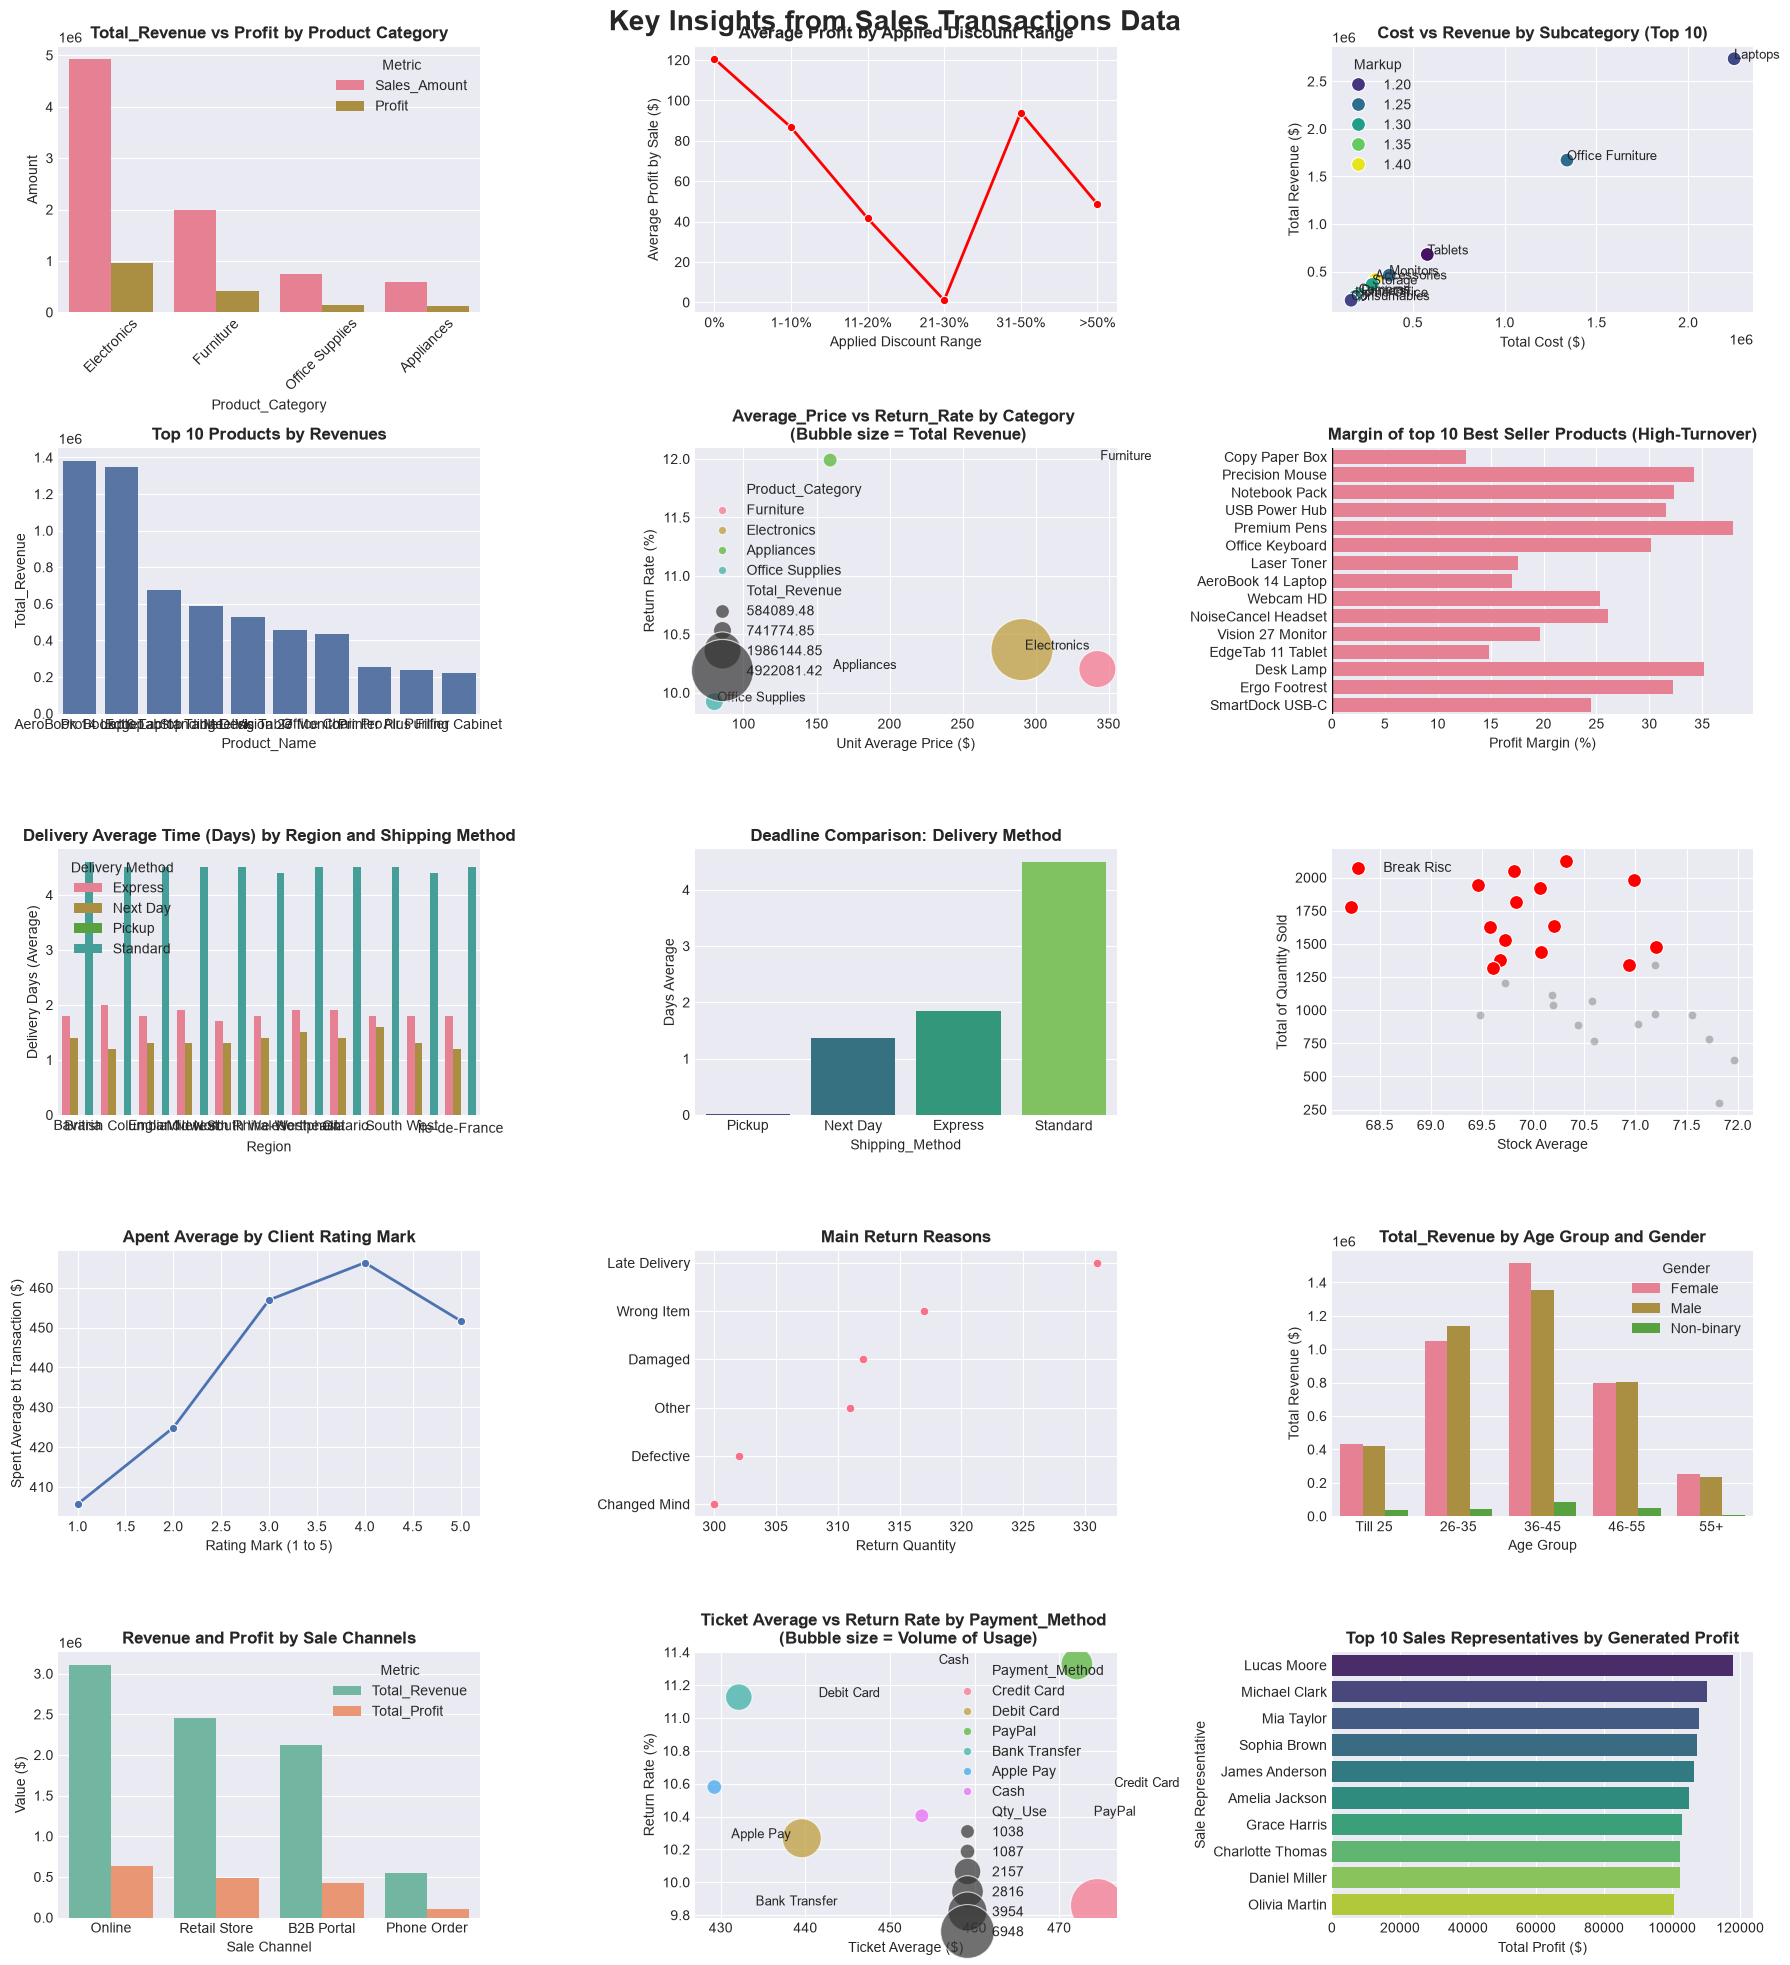

In [16]:
#6. VISUALIZATION OF KEY INSIGHTS
#Visual Setting of the Charts
fig, axes=plt.subplots(5, 3, figsize=(18, 20))
fig.suptitle("Key Insights from Sales Transactions Data", fontsize=20, fontweight="bold")

#6.1.1 Bar chart (Revenue VS Profit by Category)
melted_profit=category_profit.melt(id_vars="Product_Category", 
                                   value_vars=["Sales_Amount", "Profit"], 
                                   var_name="Metric", value_name="Amount")
sns.barplot(data=melted_profit, x="Product_Category", y="Amount", ax=axes[0, 0], hue="Metric")
axes[0, 0].set_title("Total_Revenue vs Profit by Product Category", fontweight="bold")
axes[0, 0].tick_params(axis='x', rotation=45)
plt.tight_layout()

#6.1.2. Line Chart:Average Profit by Discount Range
sns.lineplot(data=discounts_impact, x="Discount_Range", y="Profit_mean", ax=axes[0, 1], marker="o", color="red", linewidth=2)
axes[0, 1].set_title("Average Profit by Applied Discount Range", fontsize=12, fontweight="bold")
axes[0, 1].set_xlabel("Applied Discount Range")
axes[0, 1].set_ylabel("Average Profit by Sale ($)")
plt.tight_layout()

#6.1.3. Scatter Plot: top Cost vs Revenue by Subcategory
sns.scatterplot(data=top_cost_revenue, x="Cost_Amount", y="Sales_Amount", ax=axes[0, 2], s=100, hue="Markup", palette="viridis")

#Adding labels to the points
for i in range(top_cost_revenue.shape[0]):
    axes[0, 2].text(top_cost_revenue.Cost_Amount.iloc[i] +100,
                    top_cost_revenue.Sales_Amount.iloc[i],
                    top_cost_revenue.Product_Subcategory.iloc[i], fontsize=9)
axes[0, 2].set_title("Cost vs Revenue by Subcategory (Top 10)", fontweight="bold")
axes[0, 2].set_xlabel("Total Cost ($)")
axes[0, 2].set_ylabel("Total Revenue ($)")
plt.tight_layout()

#6.2.1. Curve ABC Chart (Pareto)
sns.barplot(data=product.head(10), x="Product_Name", y="Total_Revenue", color="#4C72B0", ax=axes[1, 0])
axes[1, 0].set_title("Top 10 Products by Revenues", fontweight="bold")
axes[1, 0].set_xlabel("Product_Name")
axes[1, 0].set_ylabel("Total_Revenue")
plt.tight_layout()

#6.2.2. Scatter Chart: Average Price by Category VS Return Rate
sns.scatterplot(data=category_analysis, x="Average_Price", y="Return_Rate", ax=axes[1, 1],
                size="Total_Revenue", sizes=(100, 2000), hue="Product_Category", alpha=0.7)
#Adding category names to the points
for i in range(category_analysis.shape[0]):
    axes[1, 1].text(category_analysis.Average_Price.iloc[i]+2,
                    category_analysis.Return_Rate[i],
                    category_analysis.Product_Category.iloc[i], fontsize=9)

axes[1, 1].set_title("Average_Price vs Return_Rate by Category \n (Bubble size = Total Revenue)", fontweight="bold")
axes[1, 1].set_xlabel("Unit Average Price ($)")
axes[1, 1].set_ylabel("Return Rate (%)")
plt.tight_layout()

#6.2.3 BarH Chart: High-turnover, low-Margin Products
sns.barplot(data=top_turnover, y="Product_Name", x="Margin_%", ax=axes[1, 2])
axes[1, 2].set_title("Margin of top 10 Best Seller Products (High-Turnover)", fontweight="bold")
axes[1, 2].set_xlabel("Profit Margin (%)")
axes[1, 2].set_ylabel(" ")
axes[1, 2].axvline(0, color="black", linewidth=1) #line of zero harm
plt.tight_layout()

#6.3. LOGISTIC AND OPERATIONS
#6.3.1. Bar Chart: Delivert Average time by Region and Metnhod
sns.barplot(data=logistic_region, x="Region", y="Average_Days", ax=axes[2, 0], hue="Shipping_Method")
axes[2, 0].set_title("Delivery Average Time (Days) by Region and Shipping Method", fontweight="bold")
axes[2, 0].set_ylabel("Delivery Days (Average)")
axes[2, 0].set_xlabel("Region")
axes[2, 0].legend(title="Delivery Method")
plt.tight_layout()

#6.3.2. General Delivery Average Time by Shipping Method
sns.barplot(data=time_by_method, x="Shipping_Method", y="Delivery_Days", ax=axes[2, 1], palette="viridis")
axes[2, 1].set_title("Deadline Comparison: Delivery Method", fontweight="bold")
axes[2, 1].set_ylabel("Days Average")
plt.tight_layout

#6.3.3. Scatter Chart: Stock vs Sales Quantity
sns.scatterplot(data=stock_product, x="Average_Stock", y="Total_Qty_Sales", ax=axes[2, 2], alpha=0.5, color="gray")

#Highlighting the risc points in red
sns.scatterplot(data=break_risc, x="Average_Stock", y="Total_Qty_Sales", ax=axes[2, 2], color="red", s=100, label="Break Risc")
axes[2, 2].set_xlabel("Stock Average")
axes[2, 2].set_ylabel("Total of Quantity Sold")
plt.legend()
plt.tight_layout()

#6.4.1. Line Chart: Spent Average vs Nota
sns.lineplot(data=satisfaction, x="Customer_Rating", y="Average_Spent", ax=axes[3, 0], marker="o", color="#4C72B0", linewidth=2)
axes[3, 0].set_title("Apent Average by Client Rating Mark", fontweight="bold")
axes[3, 0].set_xlabel("Rating Mark (1 to 5)")
axes[3, 0].set_ylabel("Spent Average bt Transaction ($)")
plt.tight_layout()

#6.4.2. BarH Chart: Return Reasons
sns.scatterplot(data=returning_reasons, y="Reason", x="Quantity", ax=axes[3, 1], palette="Red_r")
axes[3, 1].set_title("Main Return Reasons", fontweight="bold")
axes[3, 1].set_xlabel("Return Quantity")
axes[3, 1].set_ylabel(" ")
plt.tight_layout()

#6.4.3. Bar Chart: Revenue by Age Group and Gender
sns.barplot(data=demogr_perfil, x="Age_group", y="Sales_Amount", ax=axes[3, 2], hue="Customer_Gender")
axes[3, 2].set_title("Total_Revenue by Age Group and Gender", fontweight="bold")
axes[3, 2].set_xlabel("Age Group")
axes[3, 2].set_ylabel("Total Revenue ($)")
axes[3, 2].legend(title="Gender")
plt.tight_layout()

#6.5.1 Bar Chart: Revenue Vs Profit by Channel
melted_channels=channels.melt(id_vars="Sales_Channel", value_vars=["Total_Revenue", "Total_Profit"], var_name="Metric", value_name="Value" )
sns.barplot(data=melted_channels, x="Sales_Channel", y="Value", ax=axes[4, 0], hue="Metric", palette="Set2")
axes[4, 0].set_title("Revenue and Profit by Sale Channels", fontweight="bold")
axes[4, 0].set_ylabel("Value ($)")
axes[4, 0].set_xlabel("Sale Channel")
plt.tight_layout()

#6.5.2. Scatter Chart: Ticket Average vs Return Rate
sns.scatterplot(data=payments, x="Ticket_Average", y="Return_Rate", ax=axes[4, 1], 
                size="Qty_Use", sizes=(100, 1500), hue="Payment_Method", alpha=0.7)
for i in range (payments.shape[0]):
    axes[4, 1].text(payments.Ticket_Average.iloc[i]+2,
         payments.Return_Rate[i],
         payments.Payment_Method.iloc[i], fontsize=9)
axes[4, 1].set_title("Ticket Average vs Return Rate by Payment_Method \n (Bubble size = Volume of Usage)", fontweight="bold")
axes[4, 1].set_xlabel("Ticket Average ($)")
axes[4, 1].set_ylabel("Return Rate (%)")
plt.tight_layout()

#6.5.3. BarH chart: Top 10 Representatives by Profit
sns.barplot(data=top_representatives, y="Sales_Representative", x="Total_Profit", ax=axes[4, 2], palette="viridis")
axes[4, 2].set_title("Top 10 Sales Representatives by Generated Profit", fontweight="bold")
axes[4, 2].set_xlabel("Total Profit ($)")
axes[4, 2].set_ylabel("Sale Representative")
plt.tight_layout()